In [21]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.append(str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from src.data import clean_download, compute_losses, parkinson_variance, check_prices

In [6]:
prices = clean_download(ticker='^GSPC', start='2015-01-01')
check_prices(prices)
loss = compute_losses(prices)
parkinson_variances = parkinson_variance(prices)
df = pd.concat([loss, parkinson_variances], axis=1, join='inner')
df['sq_loss'] = df['loss'] ** 2

df

,loss,parkinson_var,sq_loss
Date,,,
2015-01-05,0.018447,0.000120,3.402997e-04
2015-01-06,0.008933,0.000127,7.980304e-05
2015-01-07,-0.011563,0.000051,1.336969e-04
2015-01-08,-0.017730,0.000096,3.143589e-04
2015-01-09,0.008439,0.000058,7.122216e-05
...,...,...,...
2026-10-13,0.000229,0.000005,5.258108e-08
2026-10-14,0.011145,0.000055,1.242153e-04
2026-10-15,-0.003249,0.000043,1.055642e-05


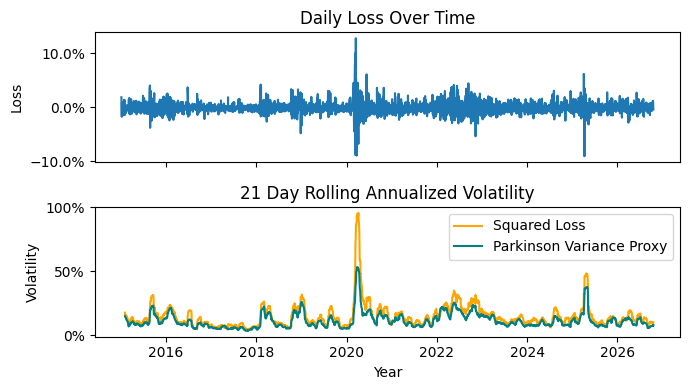

In [ ]:
fig, axes = plt.subplots(2, 1, figsize = (7, 4), sharex=True)
axes[0].plot(df['loss'])
axes[0].set_title('Daily Loss Over Time')
axes[0].set_ylabel(r"Loss")
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))

axes[1].plot(np.sqrt(252 * df["sq_loss"].rolling(21).mean()), color = 'Orange', label = "Close-to-close")
axes[1].plot(np.sqrt(252 * df['parkinson_var'].rolling(21).mean()), color = 'Teal', label = 'Parkinson (High-Low) Variance Proxy')
axes[1].set_title('21 Day Rolling Annualized Volatility')
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Volatility")
axes[1].legend()
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))

fig.tight_layout()
fig.savefig(ROOT / "results" / "losses_and_vol.png", dpi=150, bbox_inches="tight")
plt.show()